# Intervalos de confianza

In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

/home/nesper94/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


<div style="display: flex; justify-content: center;">
  <img src="https://imgs.mongabay.com/wp-content/uploads/sites/25/2026/08/28214418/oo_1742761-1200x800.jpg" alt="Niceforonia tempestuosa" style="width: 400px; object-fit: cover;">
</div>

La rana *Niceforonia tempestuosa*, tiene un tamaño promedio de $ 24 \pm 1 \text{ mm} $. Cree un conjunto de 40.000 valores con distribución normal que representarán la **población** de ranas:

In [2]:
población = np.random.normal(loc=24, scale=1, size=40000)

## La distribución t de Student

Utilice la función `generar_medias` que usamos en el notebook sobre el error estándar
y modifíquela para que no solo genere la lista de medias sino también la lista de las
desviaciones estándar de cada muestra. Además, haga que el tipo de objeto entregado
por esta función sean arreglos de numpy:

In [3]:
def generar_medias(m, n):
    medias = [] # Lista vacía para almacenar las medias de cada muestra
    stds = [] # Lista vacía para almacenar la desviación estándar de cada muestra

    for i in range(m): # Ciclo for para repetir el muestreo m veces
        muestra = np.random.choice(población, size=n) # Tomar muestra aleatoria
        media = np.mean(muestra) # Calcular promedio de la muestra
        std = np.std(muestra) # Calcular desviación estándar de la muestra
        medias.append(media) # Añadir promedio a la lista
        stds.append(std) # Añadir desviación estándar a la lista

    return np.array(medias), np.array(stds)

Genere la lista de medias y desviaciones estándar para 10.000 muestras de tamaño $ n = 5 $.

In [4]:
medias_n5, stds_n5 = generar_medias(10000, 5)

Calcule el estadístico t para cada uno de estos 10.000 valores:

In [5]:
media_poblacional = 24
t_n5 = (medias_n5 - media_poblacional)/(stds_n5/np.sqrt(5))

Repita el mismo procedimiento pero para muestras de tamaño $ n = 20 $.

In [6]:
medias_n20, stds_n20 = generar_medias(10000, 20)
t_n20 = (medias_n20 - media_poblacional)/(stds_n20/np.sqrt(20))

Grafique juntos los histogramas de los valores $ t $ calculados a partir de muestras de tamaño 5 y tamaño 20.

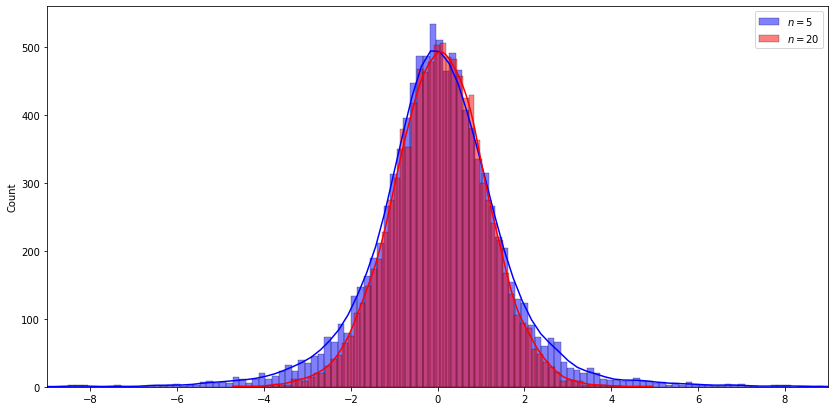

In [11]:
plt.figure(figsize=(14,7))
sns.histplot(t_n5,
             color='blue',
             kde=True,
             label='$ n = 5 $'
            )
sns.histplot(t_n20,
             alpha=0.5,
             color='red',
             kde=True,
             label='$ n = 20 $'
            )
plt.xlim(-9, 9)
plt.legend()
plt.show()